In [30]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import itertools
from tqdm import tqdm
import math
import seaborn as sns

In [31]:
def round_sig_figs(x, sig=3):
    if x == 0 or pd.isna(x):
        return x
    return round(x, sig - int(np.floor(np.log10(abs(x)))) - 1)

In [32]:
def gaussian_mutation(individual, mutation_rate=0.05, sigma=0.1):
    mutated = individual.copy()
    mask = np.random.rand(len(mutated)) < mutation_rate
    
    mutated[mask] += np.random.normal(0, sigma, size=np.sum(mask))
    return mutated

def single_point_crossover(parent1, parent2):
    k = np.random.randint(1, len(parent1))
    
    child1 = np.concatenate([parent1[:k], parent2[k:]])
    child2 = np.concatenate([parent2[:k], parent1[k:]])
    return child1, child2

In [33]:
def rank_selection(combined_population, combined_scores, pop_size):
    # łączymy rodziców i dzieci, sortujemy i ucinamy do rozmiaru populacji - selekcja rankingowa
    sorted_indices = np.argsort(combined_scores)
    best_indices = sorted_indices[:pop_size]

    population = combined_population[best_indices]
    scores = combined_scores[best_indices]    

    return population, scores

def tournament_selection(population, scores, pop_size, k=3):
    new_population = []
    new_scores = []
    
    total_pool_size = len(population)
    
    for _ in range(pop_size):
        participants_idx = np.random.choice(total_pool_size, size=k, replace=False)
        winner_idx = participants_idx[np.argmin(scores[participants_idx])]
        
        new_population.append(population[winner_idx].copy())
        new_scores.append(scores[winner_idx])
        
    return np.array(new_population), np.array(new_scores)


def roulette_wheel_selection(population, scores, pop_size):
    # elitaryzm - najlepszy osobnik przechodzi
    best_idx = np.argmin(scores)
    elite_individual = population[best_idx].copy()
    elite_score = scores[best_idx]

    worst_score = np.max(scores)
    fitness = worst_score - scores + 1e-6 
    
    probabilities = fitness / np.sum(fitness)
    
    total_pool_size = len(population)
    selected_indices = np.random.choice(total_pool_size, size=pop_size-1, p=probabilities)
    
    new_population = population[selected_indices].copy()
    new_scores = scores[selected_indices].copy()

    final_population = np.vstack((elite_individual, new_population))
    final_scores = np.append(elite_score, new_scores)
    
    return final_population, final_scores

In [34]:
class EvolutionaryAlgorithm:
    def __init__(self, objective_func, mutation_op, crossover_op, selection_op, pop_size=100, num_dimensions=5, bounds=(-5.12, 5.12), crossover_prob=0.8, mutation_prob=0.1):
        self.objective_func = objective_func
        self.mutation_op = mutation_op
        self.crossover_op = crossover_op
        self.selection_op = selection_op
        self.pop_size = pop_size
        self.num_dimensions = num_dimensions
        self.bounds = bounds

        self.crossover_prob = crossover_prob
        self.mutation_prob = mutation_prob

        # Inicjalizacja populacji - losowanie z rozkładu jednostajnego z wybranego zakresu
        low, high = self.bounds
        self.population = np.random.uniform(low, high, size=(pop_size, num_dimensions))
        
    def train(self, generations=1000):
        scores = np.array([self.objective_func(ind) for ind in self.population])
        history_best = []
        history_all = []

        # warunek stopu to dana liczba iteracji
        for gen in range(generations):
            children = []

            # KRZYŻOWANIE
            # losowe parowanie
            indices = np.arange(self.pop_size)
            np.random.shuffle(indices)

            for i in range(0, self.pop_size - 1, 2):
                parent1 = self.population[indices[i]]
                parent2 = self.population[indices[i+1]]
                
                if np.random.rand() < self.crossover_prob:
                    child1, child2 = self.crossover_op(parent1, parent2)
                else:
                    child1, child2 = parent1.copy(), parent2.copy()
                    
                children.extend([child1, child2])

            # MUTACJA
            mutated_children = []
            for child in children:
                if np.random.rand() < self.mutation_prob:
                    mutated_children.append(self.mutation_op(child))
                else:
                    mutated_children.append(child)
            
            mutated_children = np.array(mutated_children)

            # EWALUACJA
            children_scores = np.array([self.objective_func(c) for c in mutated_children])

            # SELEKCJA
            combined_population = np.vstack((self.population, mutated_children))
            combined_scores = np.concatenate((scores, children_scores))
            self.population, scores = self.selection_op(combined_population, combined_scores, self.pop_size)

            best_current_score = np.min(scores)
            avg_current_score = np.mean(scores)
            
            history_best.append(best_current_score)
            history_all.append(scores.copy())
        
        best_idx = np.argmin(scores)
        best_individual = self.population[best_idx]
        best_score = scores[best_idx]
        
        return best_individual, best_score, history_best, history_all

In [35]:
def train_N(objective_func, bounds, num_dimensions, param_grid, N=10):
    keys = param_grid.keys()
    combinations = list(itertools.product(*param_grid.values()))
    
    summary_results = []
    raw_results = []
    
    for combo in tqdm(combinations, desc="Postęp kombinacji", unit="kombinacja"):
        params = dict(zip(keys, combo))
        selection_name = params['selection_op'].__name__
        
        scores_for_this_combo = []

        best_overall_score = float('inf') 
        best_overall_individual = None
        
        for _ in range(N):
            ea = EvolutionaryAlgorithm(
                objective_func=objective_func,
                mutation_op=gaussian_mutation,
                crossover_op=single_point_crossover,
                selection_op=params['selection_op'],
                pop_size=params['pop_size'],
                num_dimensions=num_dimensions,
                bounds=bounds,
                crossover_prob=params['crossover_prob'],
                mutation_prob=params['mutation_prob']
            )
            
            best_individual, best_score, _, _ = ea.train(generations=params['generations'])
            scores_for_this_combo.append(best_score)

            if best_score < best_overall_score:
                best_overall_score = best_score
                best_overall_individual = best_individual.copy()
            
            raw_results.append({
                'Selection': selection_name,
                'Pop Size': params['pop_size'],
                'Cross Prob': params['crossover_prob'],
                'Mut Prob': params['mutation_prob'],
                'Score': best_score
            })
            
        summary_results.append({
            'Selection': selection_name,
            'Pop Size': params['pop_size'],
            'Cross Prob': params['crossover_prob'],
            'Mut Prob': params['mutation_prob'],
            'Mean Score': np.mean(scores_for_this_combo),
            'Std Dev': np.std(scores_for_this_combo),
            'Min': np.min(scores_for_this_combo),
            'Max': np.max(scores_for_this_combo),
            'Best Solution': best_overall_individual
        })

    raw_df = pd.DataFrame(raw_results)
    ordered_selection_names = [op.__name__ for op in param_grid['selection_op']]
    
    for sel_name in ordered_selection_names:
        df_sel = raw_df[raw_df['Selection'] == sel_name]
        
        if df_sel.empty:
            continue
            
        unique_pops = sorted(df_sel['Pop Size'].unique())
        num_pops = len(unique_pops)
        
        fig, axes = plt.subplots(1, num_pops, figsize=(6 * num_pops, 6), sharey=True)
        if num_pops == 1:
            axes = [axes]
            
        fig.suptitle(f"Metoda selekcji: {sel_name}", fontsize=18, fontweight='bold')
        
        for ax, pop in zip(axes, unique_pops):
            df_pop = df_sel[df_sel['Pop Size'] == pop]
            
            sns.boxplot(
                data=df_pop, 
                x='Cross Prob', 
                y='Score', 
                hue='Mut Prob', 
                ax=ax, 
                palette='Set2'
            )
            
            ax.set_yscale('log')
            ax.set_title(f"Rozmiar populacji: {pop}", fontsize=14)
            ax.set_xlabel("Prawdopodobieństwo krzyżowania", fontsize=12)
            
            if ax == axes[0]:
                ax.set_ylabel("Najlepszy wynik (skala log)", fontsize=12)
            else:
                ax.set_ylabel("")
                
            ax.grid(True, alpha=0.3, axis='y')
            
            ax.legend(title='Prawd. mutacji', fontsize=10, title_fontsize=11)

        plt.tight_layout()
        plt.show()
    
    results_df = pd.DataFrame(summary_results)
    cols_to_round = ['Mean Score', 'Std Dev', 'Min', 'Max']
    for col in cols_to_round:
        results_df[col] = results_df[col].apply(lambda val: round_sig_figs(val, sig=3))
        
    results_df['Best Solution'] = results_df['Best Solution'].apply(
        lambda wektor: [round_sig_figs(wspolrzedna, sig=3) for wspolrzedna in wektor]
    )
    
    return results_df.sort_values(by='Mean Score').reset_index(drop=True)

# Funkcja $x^2+y^2+2z^2$

In [36]:
def function_3d(x):
    return x[0]**2 + x[1]**2 + 2*x[2]**2

Postęp kombinacji: 100%|██████████| 81/81 [00:57<00:00,  1.40kombinacja/s]


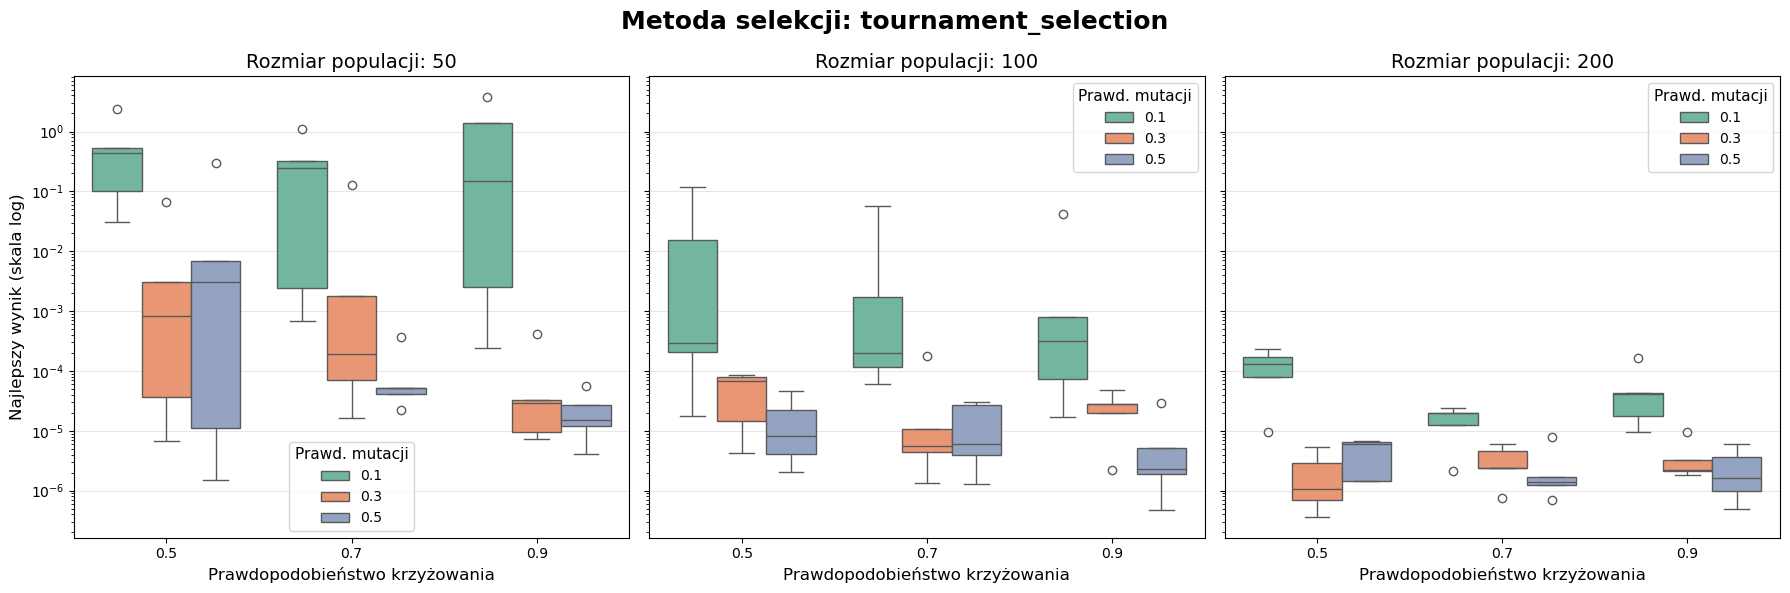

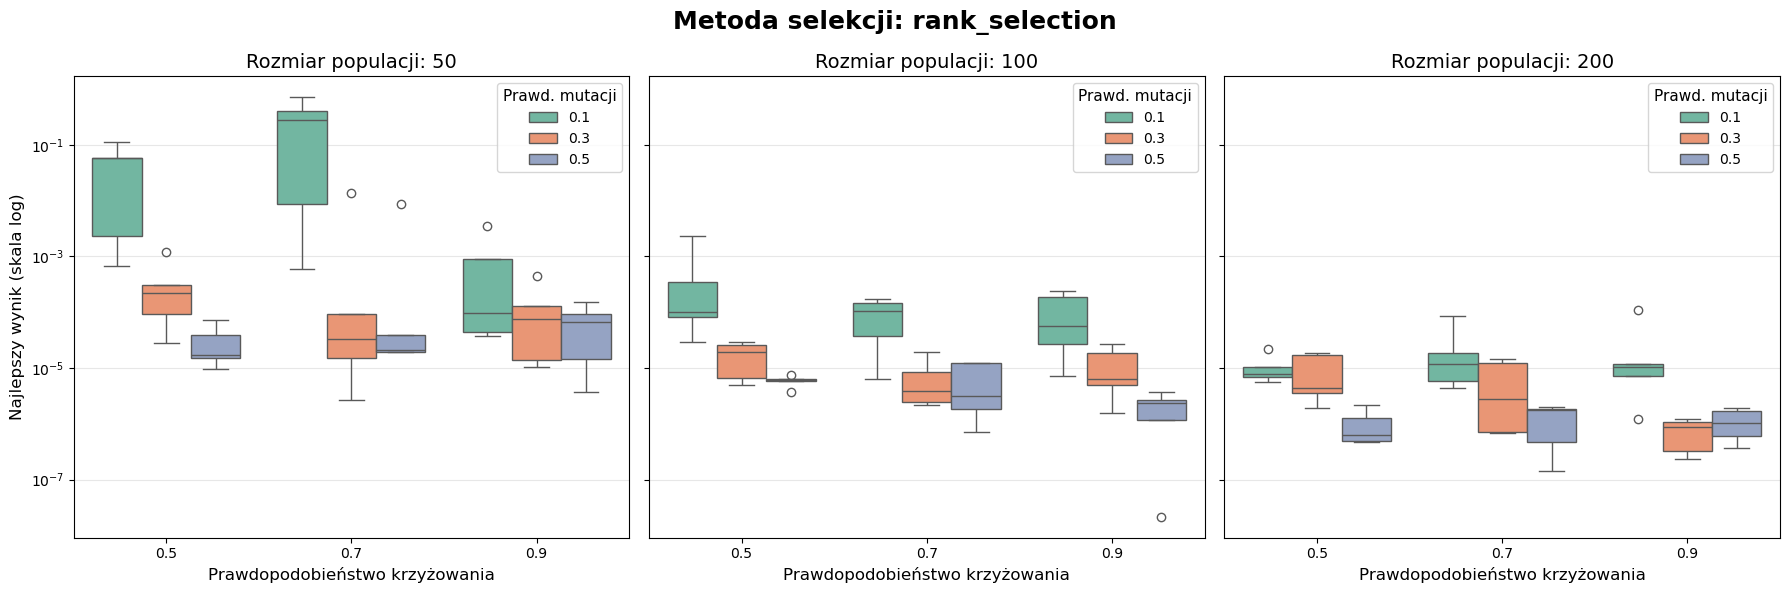

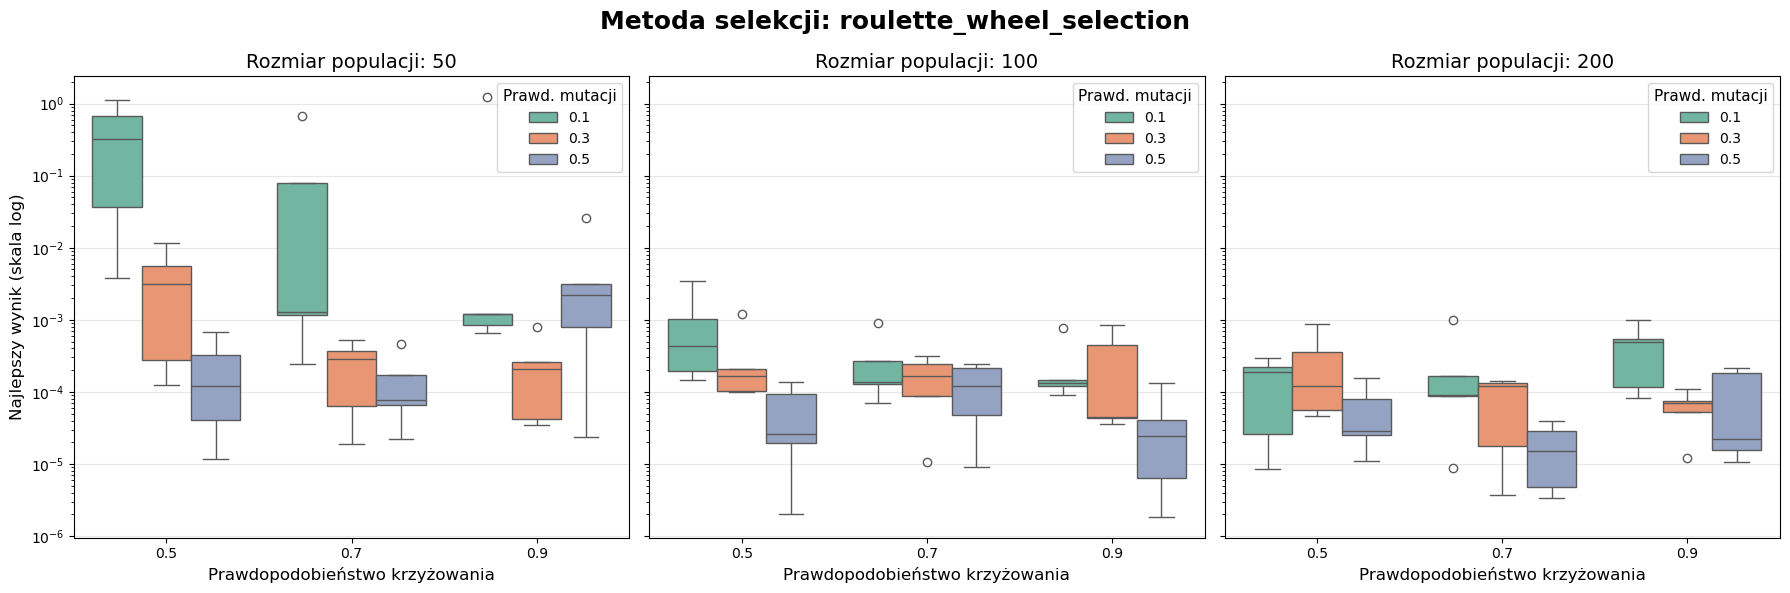

,Selection,Pop Size,Cross Prob,Mut Prob,Mean Score,Std Dev,Min,Max,Best Solution
0,rank_selection,200,0.9,0.3,7.430000e-07,3.950000e-07,2.300000e-07,0.000001,"[0.000126, 0.000463, -6.9e-06]"
1,rank_selection,200,0.5,0.5,1.010000e-06,6.540000e-07,4.740000e-07,0.000002,"[4.74e-06, 0.000253, 0.000453]"
2,rank_selection,200,0.9,0.5,1.120000e-06,5.980000e-07,3.660000e-07,0.000002,"[9.94e-05, 0.000203, 0.000397]"
3,rank_selection,200,0.7,0.5,1.240000e-06,7.740000e-07,1.450000e-07,0.000002,"[4.43e-05, -8.18e-05, 0.000261]"
4,rank_selection,100,0.9,0.5,2.000000e-06,1.290000e-06,2.160000e-08,0.000004,"[0.000145, -6.81e-06, -1.53e-05]"
...,...,...,...,...,...,...,...,...,...
76,rank_selection,50,0.7,0.1,2.800000e-01,2.650000e-01,5.910000e-04,0.709000,"[0.0149, -0.0105, -0.0113]"
77,tournament_selection,50,0.7,0.1,3.370000e-01,4.100000e-01,6.800000e-04,1.120000,"[-0.00647, -0.0134, 0.0152]"
78,roulette_wheel_selection,50,0.5,0.1,4.350000e-01,4.260000e-01,3.770000e-03,1.140000,"[0.0364, 0.0428, -0.0175]"
79,tournament_selection,50,0.5,0.1,6.920000e-01,8.600000e-01,3.140000e-02,2.370000,"[-0.0726, -0.16, -0.014]"


In [37]:
param_grid_3d = {
    'selection_op': [tournament_selection, rank_selection, roulette_wheel_selection],
    'pop_size': [50, 100, 200],
    'crossover_prob': [0.5, 0.7, 0.9],
    'mutation_prob': [0.1, 0.3, 0.5],
    'generations': [100]
}

results_table = train_N(
    objective_func=function_3d, 
    bounds=(-10.0, 10.0), 
    num_dimensions=3, 
    param_grid=param_grid_3d,
    N=5
)

results_table.to_csv("AE1_3d.csv")
results_table

# Funkcja Rastrigina

In [38]:
def rastrigin(x, A=10):
    x = np.array(x)
    n = len(x)
    return A * n + np.sum(x**2 - A * np.cos(2 * np.pi * x))

Postęp kombinacji: 100%|██████████| 81/81 [01:27<00:00,  1.08s/kombinacja]


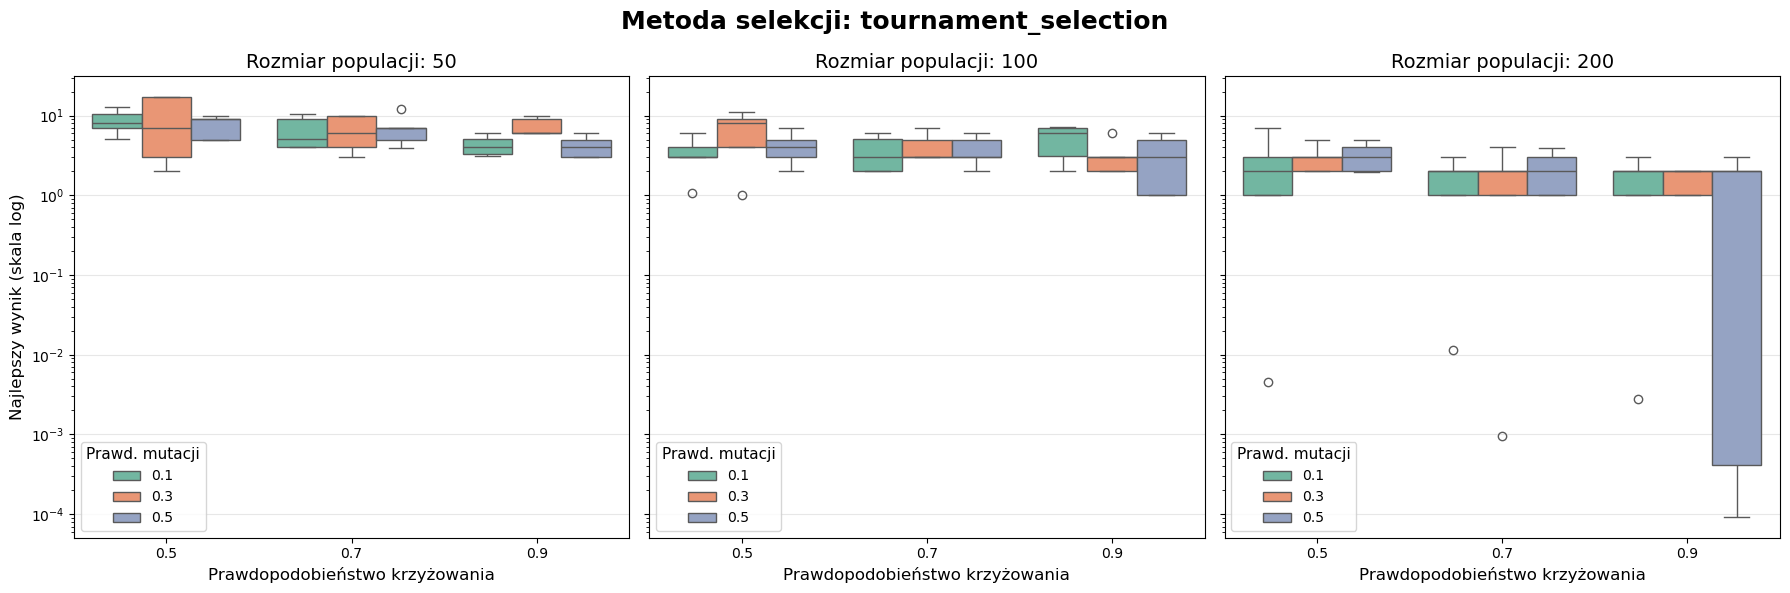

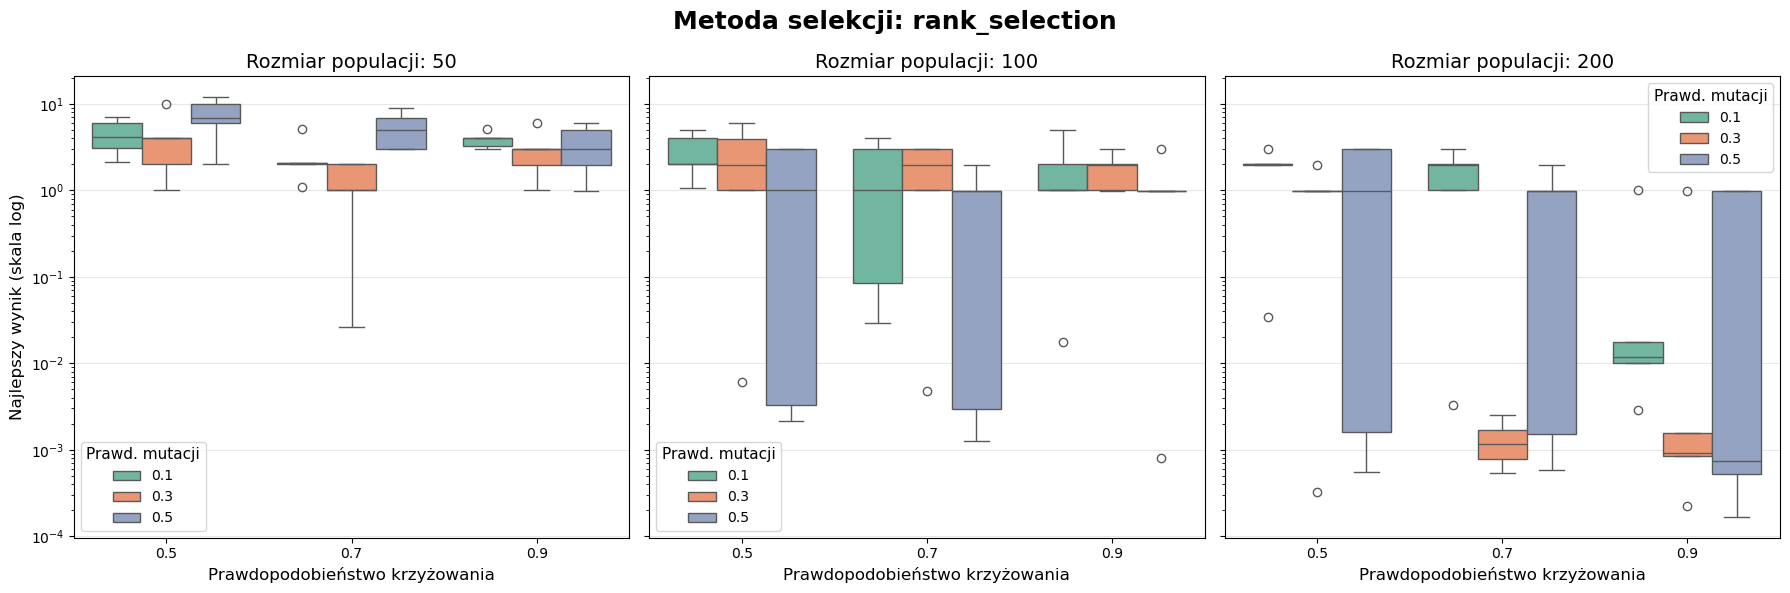

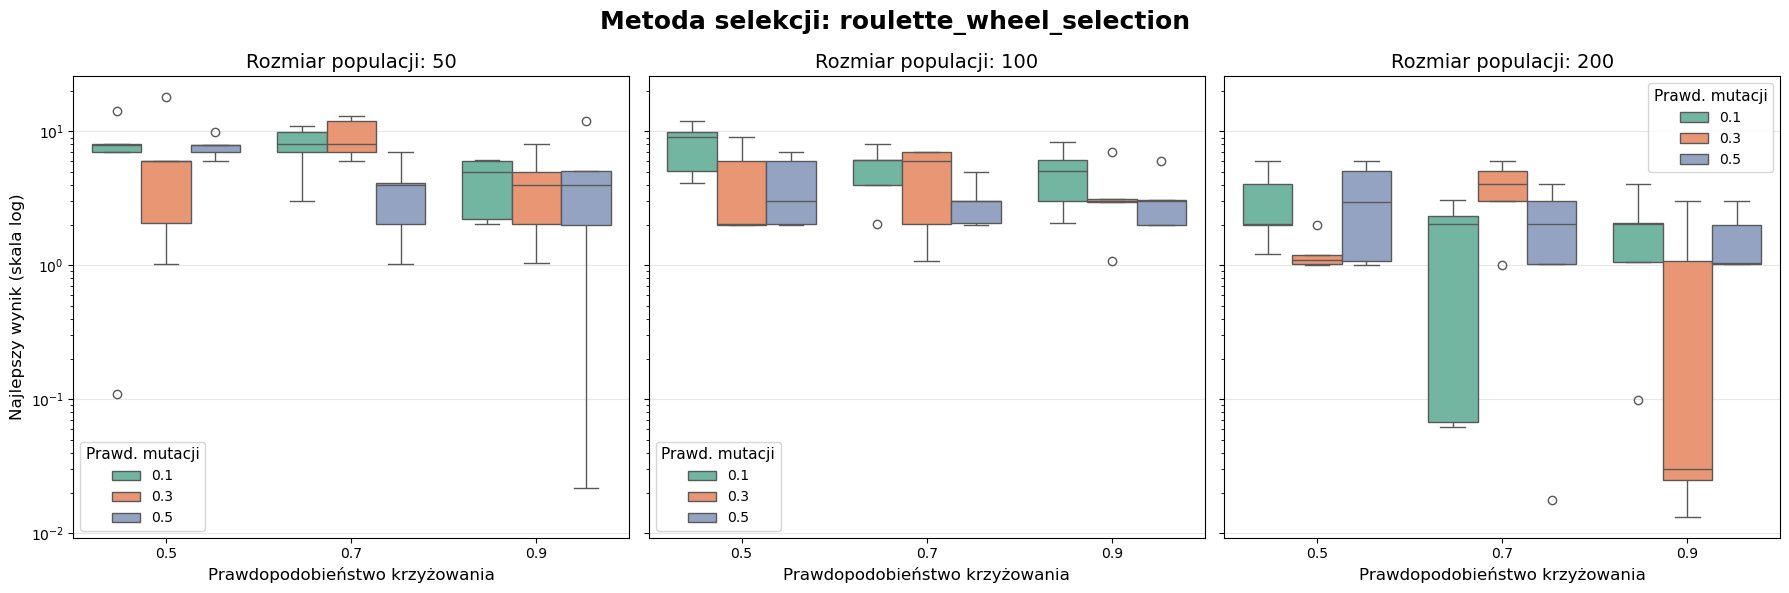

,Selection,Pop Size,Cross Prob,Mut Prob,Mean Score,Std Dev,Min,Max,Best Solution
0,rank_selection,200,0.7,0.3,0.00134,0.000707,0.000544,0.00253,"[-0.000121, -0.000439, 0.000889, -0.000125, 0...."
1,rank_selection,200,0.9,0.3,0.20000,0.398000,0.000222,0.99700,"[1.85e-05, -0.000225, 0.000746, 0.000493, -0.0..."
2,rank_selection,200,0.9,0.1,0.20800,0.396000,0.002860,1.00000,"[0.000994, 0.000308, 0.00302, -0.000983, -0.00..."
3,rank_selection,200,0.9,0.5,0.39800,0.487000,0.000168,0.99600,"[0.000135, 0.000374, 0.000137, -0.000665, -0.0..."
4,rank_selection,200,0.7,0.5,0.79700,0.744000,0.000575,1.99000,"[-0.000583, 0.000671, -0.000651, -6.09e-05, 0...."
...,...,...,...,...,...,...,...,...,...
76,roulette_wheel_selection,50,0.7,0.1,7.80000,2.780000,3.010000,11.00000,"[0.997, -0.993, -0.0067, 1.0, 0.00654]"
77,roulette_wheel_selection,100,0.5,0.1,8.03000,3.000000,4.090000,12.00000,"[1.0, -0.974, -0.993, 0.00149, -1.0]"
78,tournament_selection,50,0.5,0.1,8.72000,2.730000,5.070000,13.00000,"[-0.0125, -1.99, -0.0097, -0.000924, 0.981]"
79,tournament_selection,50,0.5,0.3,9.18000,6.560000,2.000000,17.00000,"[0.00174, -0.993, -0.00379, -0.996, -0.00433]"


In [39]:
param_grid_3d = {
    'selection_op': [tournament_selection, rank_selection, roulette_wheel_selection],
    'pop_size': [50, 100, 200],
    'crossover_prob': [0.5, 0.7, 0.9],
    'mutation_prob': [0.1, 0.3, 0.5],
    'generations': [100]
}

results_table = train_N(
    objective_func=rastrigin, 
    bounds=(-5.12, 5.12), 
    num_dimensions=5, 
    param_grid=param_grid_3d,
    N=5
)

results_table.to_csv("AE1_rastrigin.csv")
results_table